# Recomendação de freelancers para vagas da UmFreela

**Trabalho avaliativo, Módulo 8: Machine Learning Aplicado** (Profa. Rhauani Weber Aita Fazul)
**Aluno:** Jonathan Gonçalves Possa · Especialização em Ciência de Dados e Inteligência Artificial (AMF)
**Proposta escolhida:** Alternativa A, Machine Learning tradicional (classificação + recomendação)

Repositório: https://github.com/Jonathanpossa/umfreela-recomendacao-freelancers

**Sumário**
1. Dataset: link e descrição
2. Definição do problema e objetivo
3. Análise exploratória
4. Limpeza e tratamento dos dados
5. Engenharia de atributos, codificação e padronização
6. Divisão em treino, validação e teste
7. Linha de base sem ML
8. Modelo v1 (regressão logística)
9. Refinamento: modelo v2 (novos atributos, comparação de algoritmos e ajuste de hiperparâmetros)
10. Avaliação final no teste e análise de overfitting
11. Interpretação do modelo
12. Recomendação: exemplos de predições e ação sugerida
13. Limitações e possibilidades de evolução

In [1]:
# Preparação do ambiente (no Google Colab o repositório é clonado automaticamente)
import os, sys
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone -q https://github.com/Jonathanpossa/umfreela-recomendacao-freelancers.git
    %cd umfreela-recomendacao-freelancers
sys.path.insert(0, "src")

import warnings; warnings.filterwarnings("ignore")
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance
import gerar_dados, preparo as P, modelos as M, recomendador as R

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("reports/figuras"); FIG.mkdir(parents=True, exist_ok=True)
Path("models").mkdir(exist_ok=True)
AZUL, LARANJA, CINZA = "#2a78d6", "#e8833a", "#8a8984"
if not Path("data/candidaturas.csv").exists():
    print(gerar_dados.gerar())

## 1. Dataset: link e descrição

**Link:** pasta [`data/`](https://github.com/Jonathanpossa/umfreela-recomendacao-freelancers/tree/main/data) do repositório (quatro arquivos CSV).

A UmFreela é uma plataforma que conecta restaurantes, bares e hotéis a freelancers do setor (garçom, cozinheiro, bartender e outras funções) em seis cidades do RS. Como os dados reais têm informações pessoais de freelancers (LGPD), o conjunto foi **gerado por simulação** (`src/gerar_dados.py`, semente 42) seguindo as regras do negócio: o restaurante publica uma vaga, freelancers se candidatam, o restaurante contrata um deles e, depois do turno, avalia o trabalho. A simulação também insere problemas de qualidade parecidos com os de produção.

| Arquivo | Linhas | Conteúdo |
|---|---|---|
| `freelancers.csv` | 1.800 | cidade, localização (km), funções, experiência, turnos concluídos, nota média, taxas de falta e cancelamento, pretensão de diária, disponibilidade, curso, tempo de resposta, perfil |
| `restaurantes.csv` | 320 | cidade, localização (km), segmento |
| `vagas.csv` | 7.000 | restaurante, função, data de publicação e do turno, período, valor da diária, antecedência |
| `candidaturas.csv` | ~49 mil | par (vaga, freelancer), distância, se foi contratado e se o match deu certo |

**Alvo (`match_sucesso`)**: 1 quando o freelancer foi contratado, compareceu ao turno e recebeu nota 4 ou 5; 0 nos demais casos. Período: 01/10/2025 a 30/09/2026.

In [2]:
dados = P.carregar()
for nome, df in dados.items():
    print(f"{nome:13s} {df.shape[0]:>6} linhas x {df.shape[1]} colunas")
dados["candidaturas"].head()

freelancers     1800 linhas x 20 colunas
restaurantes     320 linhas x 5 colunas
vagas           7000 linhas x 8 colunas
candidaturas   49727 linhas x 6 colunas


,id_vaga,id_freela,data_candidatura,distancia_km,contratado,match_sucesso
0,V00001,F01654,2025-10-01 19:29,2.67,1,0
1,V00001,F00188,2025-10-01 20:15,4.64,0,0
2,V00001,F00444,2025-10-01 23:26,2.95,0,0
3,V00002,F01149,2025-10-01 11:55,1.58,0,0
4,V00002,F00504,2025-10-01 11:56,4.59,0,0


## 2. Definição do problema e objetivo

Quando um restaurante publica uma vaga, recebe em média 7 candidaturas e escolhe na hora, muitas vezes sem saber quem é mais confiável. Do outro lado, a vaga pode ficar sem ninguém se os freelancers certos não a virem a tempo. Hoje a lista de candidatos é ordenada pela nota média, o que ignora distância, faltas anteriores, disponibilidade e histórico com o próprio restaurante.

**Problema de ML:** classificação binária. Para cada par (vaga, freelancer), estimar a probabilidade de o match dar certo.

**Objetivo de negócio:** usar essa probabilidade para **recomendar** os melhores freelancers de cada vaga, de duas formas:
- ordenar os candidatos para o restaurante escolher;
- convidar ativamente os freelancers elegíveis com maior chance de sucesso, antes mesmo de se candidatarem.

Com a maior probabilidade entre os candidatos de cada vaga, o sistema também sugere uma **ação**: destacar o melhor candidato, ampliar os convites ou, quando o risco de não preencher é alto, disparar uma nova rodada de convites e avisar o restaurante.

**Como medir:** métricas de classificação (precisão, revocação, F1, ROC-AUC, PR-AUC, matriz de confusão) e métricas de recomendação por vaga: HitRate@k (o freelancer que deu certo estava entre os k primeiros?) e MRR.

## 3. Análise exploratória
### 3.1 Tipos, faltantes e duplicados

In [3]:
cand, fre = dados["candidaturas"], dados["freelancers"]
print("Tipos das colunas de freelancers:"); print(fre.dtypes.value_counts().to_string())
faltantes = pd.concat({n: d.isna().sum() for n, d in dados.items()}).loc[lambda s: s > 0]
print("\nValores faltantes por coluna:"); print(faltantes.to_string())
print("\nCandidaturas duplicadas (mesma vaga e freelancer):", cand.duplicated(["id_vaga", "id_freela"]).sum())

Tipos das colunas de freelancers:
float64    9
int64      6
str        5

Valores faltantes por coluna:
freelancers   funcao_secundaria     726
              nota_media             34
              taxa_no_show           34
              taxa_cancelamento      34
              tempo_resposta_min     82
candidaturas  distancia_km          511

Candidaturas duplicadas (mesma vaga e freelancer): 735


Os faltantes têm causas diferentes e por isso recebem tratamentos diferentes:
- `nota_media`, `taxa_no_show` e `taxa_cancelamento` vazios são freelancers **sem nenhum turno concluído**. Não é erro: vira o atributo `sem_historico` e o valor é imputado pela mediana;
- `tempo_resposta_min` vazio é falha de registro do app: imputado pela mediana dentro do pipeline;
- `distancia_km` vazia ou com erro pode ser **recalculada** pelas coordenadas do restaurante e do freelancer.

In [4]:
P.diagnostico(dados)

,tabela,problema,registros
0,freelancers,cidade fora do padrão,104
1,freelancers,pretensão de diária inválida (< R$ 50 ou > R$ ...,21
2,freelancers,tempo de resposta faltante,82
3,freelancers,sem histórico (nota e taxas vazias),34
4,candidaturas,candidatura duplicada (mesma vaga e freelancer),735
5,candidaturas,distância faltante,511
6,candidaturas,"distância fora da faixa (> 50 km, erro de GPS)",134


### 3.2 Outliers

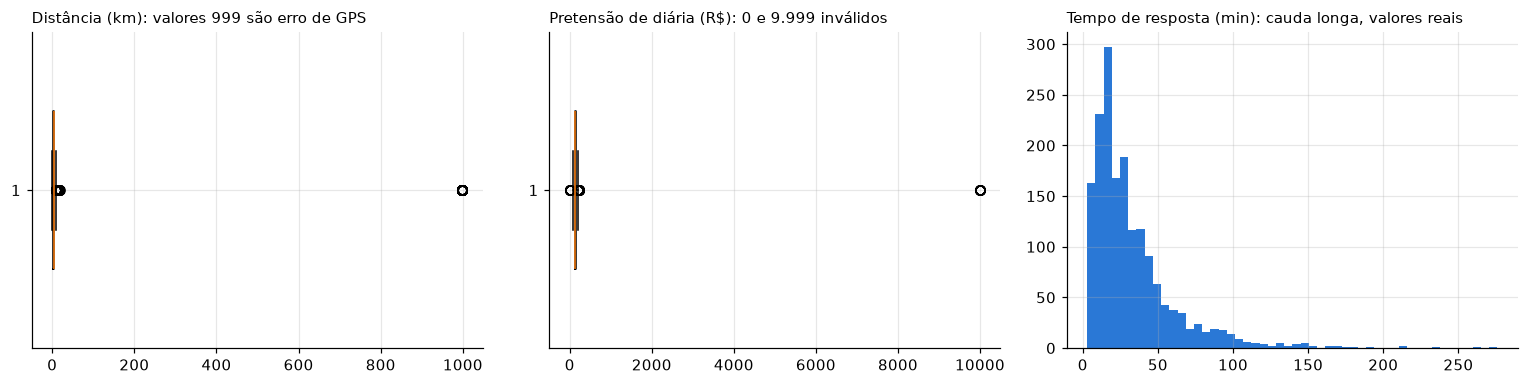

cidade
Santa Maria       548
Porto Alegre      490
Uruguaiana        193
Quarta Colônia    181
Santiago          155
Itaqui            129
 Santa Maria       17
 Porto Alegre      13
PORTO ALEGRE       13
santa maria        12
porto alegre        9
URUGUAIANA          8
 Uruguaiana         6
SANTA MARIA         6
 Santiago           5
 Itaqui             3
itaqui              3
santiago            2
quarta colônia      2
uruguaiana          2
QUARTA COLÔNIA      1
ITAQUI              1
SANTIAGO            1


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].boxplot(cand.distancia_km.dropna(), vert=False, widths=0.5)
ax[0].set_title("Distância (km): valores 999 são erro de GPS", loc="left", fontsize=10)
ax[1].boxplot(fre.pretensao_diaria, vert=False, widths=0.5)
ax[1].set_title("Pretensão de diária (R$): 0 e 9.999 inválidos", loc="left", fontsize=10)
ax[2].hist(fre.tempo_resposta_min.dropna(), bins=50, color=AZUL)
ax[2].set_title("Tempo de resposta (min): cauda longa, valores reais", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "01_outliers.png", bbox_inches="tight"); plt.show()
print(fre.cidade.value_counts().to_string())

- **Distância 999 km** e **pretensão R$ 0 ou R$ 9.999** são erros de registro: tratados como faltantes e corrigidos (seção 4).
- O **tempo de resposta** tem cauda longa, mas os valores são plausíveis (há quem demore horas para responder). São mantidos; a padronização e o modelo baseado em árvores lidam com a escala.
- A coluna **cidade** tem variações de escrita (maiúsculas, espaços, sem acento) que precisam ser padronizadas.

### 3.3 Alvo e relação com os atributos

Taxa de match bem-sucedido: 9.4%  (classe desbalanceada)
Vagas com pelo menos um match: 65.9%
Candidaturas por vaga: média 7.0


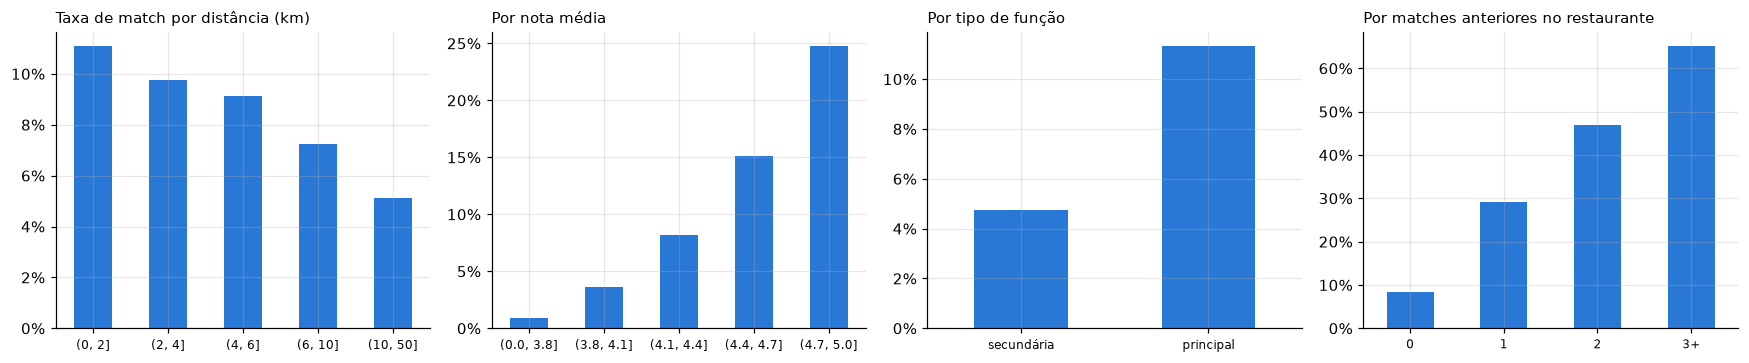

In [6]:
c = cand.drop_duplicates(["id_vaga", "id_freela"])
print(f"Taxa de match bem-sucedido: {c.match_sucesso.mean():.1%}  (classe desbalanceada)")
print(f"Vagas com pelo menos um match: {c.groupby('id_vaga').match_sucesso.max().mean():.1%}")
print(f"Candidaturas por vaga: média {c.groupby('id_vaga').size().mean():.1f}")

limpos_tmp = P.limpar(dados); base_tmp = P.construir_base(limpos_tmp)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
faixas = pd.cut(base_tmp.distancia_km, [0, 2, 4, 6, 10, 50])
base_tmp.groupby(faixas, observed=True).match_sucesso.mean().plot.bar(ax=ax[0], color=AZUL)
ax[0].set_title("Taxa de match por distância (km)", loc="left", fontsize=10)
base_tmp.groupby(pd.cut(base_tmp.nota_media, [0, 3.8, 4.1, 4.4, 4.7, 5]), observed=True).match_sucesso.mean().plot.bar(ax=ax[1], color=AZUL)
ax[1].set_title("Por nota média", loc="left", fontsize=10)
base_tmp.groupby("funcao_principal_igual").match_sucesso.mean().rename({0: "secundária", 1: "principal"}).plot.bar(ax=ax[2], color=AZUL)
ax[2].set_title("Por tipo de função", loc="left", fontsize=10)
base_tmp.groupby(base_tmp.matches_previos_restaurante.clip(upper=3)).match_sucesso.mean().rename({3: "3+"}).plot.bar(ax=ax[3], color=AZUL)
ax[3].set_title("Por matches anteriores no restaurante", loc="left", fontsize=10)
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=0, labelsize=8); a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(FIG / "02_relacoes_alvo.png", bbox_inches="tight"); plt.show()

- Só **~9,5%** das candidaturas terminam em match bem-sucedido: a classe positiva é minoritária. Por isso a avaliação usa PR-AUC e F1, e não só acurácia (um modelo que sempre diz "não" teria 90% de acurácia).
- A taxa de sucesso cai com a distância e sobe com a nota, com a função principal e, sobretudo, com o **histórico de trabalhos anteriores no mesmo restaurante**. São sinais fortes para o modelo.

## 4. Limpeza e tratamento dos dados

In [7]:
limpos = P.limpar(dados)
antes, depois = dados["candidaturas"], limpos["candidaturas"]
print(f"Candidaturas: {len(antes)} -> {len(depois)} (removidas {len(antes) - len(depois)} duplicadas)")
print("Cidades após padronização:", sorted(limpos["freelancers"].cidade.unique()))
print("Pretensão de diária (R$): min", limpos["freelancers"].pretensao_diaria.min(), "| max", limpos["freelancers"].pretensao_diaria.max())
print("Distância (km): faltantes", depois.distancia_km.isna().sum(), "| max", depois.distancia_km.max())

Candidaturas: 49727 -> 48992 (removidas 735 duplicadas)
Cidades após padronização: ['Itaqui', 'Porto Alegre', 'Quarta Colônia', 'Santa Maria', 'Santiago', 'Uruguaiana']
Pretensão de diária (R$): min 90.0 | max 230.0
Distância (km): faltantes 0 | max 17.86


| Problema | Tratamento |
|---|---|
| Candidatura duplicada | mantida a primeira ocorrência |
| Cidade fora do padrão | normalização (maiúsculas, espaços e acentos) para os 6 nomes oficiais |
| Pretensão de diária inválida | substituída pela mediana da mesma função |
| Distância faltante ou > 50 km | recalculada pelas coordenadas do restaurante e do freelancer |
| Nota e taxas vazias (sem histórico) | atributo `sem_historico` + imputação pela mediana no pipeline |
| Tempo de resposta faltante | imputação pela mediana no pipeline |

## 5. Engenharia de atributos, codificação e padronização

Cada linha da base de modelagem é um par (vaga, freelancer) com informações disponíveis **no momento da publicação da vaga**.

| Atributo criado | Como é calculado |
|---|---|
| `funcao_principal_igual`, `funcao_secundaria_igual` | a função da vaga é a principal ou a secundária do freelancer |
| `diferenca_diaria_pct` | (diária oferecida − pretensão) / diária oferecida |
| `disponivel_no_turno` | disponibilidade no período (manhã, tarde, noite) e no fim de semana, se for o caso |
| `turno_fim_semana` | turno no sábado ou domingo |
| `log_turnos_concluidos` | log(1 + turnos concluídos), para reduzir a assimetria |
| `sem_historico` | freelancer sem nenhum turno concluído |
| `matches_previos_restaurante` | matches bem-sucedidos anteriores do mesmo par restaurante e freelancer, contando **só vagas publicadas antes** (sem vazamento de informação do futuro) |

**Codificação:** `funcao`, `cidade`, `periodo` e `segmento` com One-Hot Encoding.
**Padronização:** StandardScaler nas variáveis numéricas da regressão logística (sensível à escala). Nos modelos de árvore a padronização é dispensada.
Tudo isso fica dentro de um `Pipeline` do scikit-learn, ajustado só com dados de treino.

(48992, 29)
Atributos v1: ['distancia_km', 'funcao_principal_igual', 'nota_media', 'anos_experiencia', 'diferenca_diaria_pct', 'funcao', 'cidade']
Atributos v2: ['distancia_km', 'funcao_principal_igual', 'nota_media', 'anos_experiencia', 'diferenca_diaria_pct', 'funcao_secundaria_igual', 'disponivel_no_turno', 'turno_fim_semana', 'log_turnos_concluidos', 'sem_historico', 'taxa_no_show', 'taxa_cancelamento', 'matches_previos_restaurante', 'possui_curso', 'tempo_resposta_min', 'perfil_completo_pct', 'valor_diaria', 'horas_antecedencia', 'funcao', 'cidade', 'periodo', 'segmento']


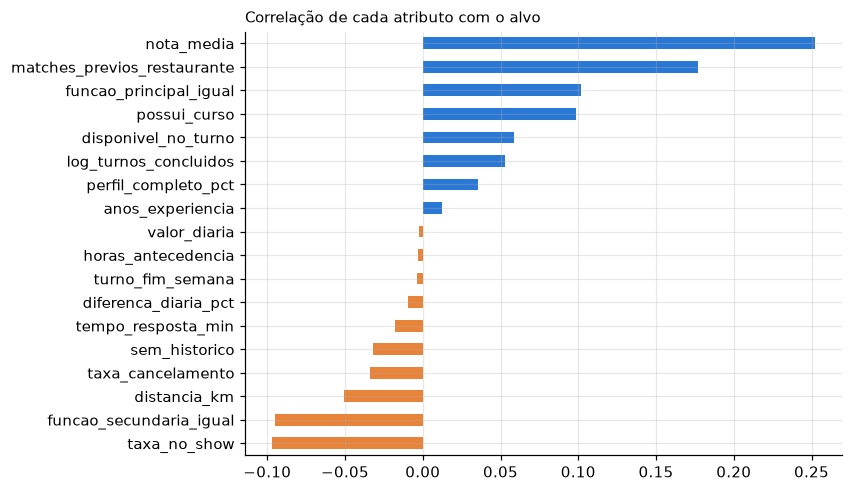

In [8]:
base = P.construir_base(limpos)
print(base.shape)
print("Atributos v1:", P.FEATURES_V1)
print("Atributos v2:", P.FEATURES_V2)
corr = base[P.NUMERICAS_V2 + ["match_sucesso"]].corr()["match_sucesso"].drop("match_sucesso").sort_values()
corr.plot.barh(figsize=(7, 5), color=[LARANJA if v < 0 else AZUL for v in corr])
plt.title("Correlação de cada atributo com o alvo", loc="left", fontsize=10)
plt.savefig(FIG / "03_correlacao.png", bbox_inches="tight"); plt.show()

## 6. Divisão em treino, validação e teste

- **Teste:** vagas publicadas a partir de **01/07/2026** (julho a setembro, ~32% das linhas). A divisão é **temporal**, como seria em produção: o modelo é treinado com o passado e avaliado no futuro.
- **Treino:** vagas de outubro/2025 a junho/2026.
- **Validação:** validação cruzada com 5 dobras dentro do treino, **agrupada por vaga** (`GroupKFold`), para que os candidatos de uma mesma vaga nunca fiquem divididos entre treino e validação. É usada para comparar algoritmos, ajustar hiperparâmetros e escolher o limiar de decisão.

In [9]:
treino, teste = base[base.conjunto == "treino"].reset_index(drop=True), base[base.conjunto == "teste"].reset_index(drop=True)
y_tr, y_te, grupos = treino.match_sucesso, teste.match_sucesso, treino.id_vaga
pd.DataFrame({"linhas": [len(treino), len(teste)], "vagas": [treino.id_vaga.nunique(), teste.id_vaga.nunique()],
              "taxa_match": [y_tr.mean(), y_te.mean()],
              "período": [f"{treino.data_publicacao.min():%d/%m/%Y} a {treino.data_publicacao.max():%d/%m/%Y}",
                          f"{teste.data_publicacao.min():%d/%m/%Y} a {teste.data_publicacao.max():%d/%m/%Y}"]},
             index=["treino", "teste"])

,linhas,vagas,taxa_match,período
treino,33540,4768,0.093143,01/10/2025 a 30/06/2026
teste,15452,2232,0.096428,01/07/2026 a 30/09/2026


## 7. Linha de base sem ML

Regra usada hoje: ordenar os candidatos pela **nota média** e, no empate, pela distância. Serve de referência: o modelo só vale a pena se recomendar melhor do que isso.

In [10]:
teste["score_regra"] = M.score_heuristico(teste)
rank_regra = M.metricas_ranking(teste, "score_regra")
pd.Series(rank_regra, name="regra atual").round(3).to_frame()

,regra atual
hit_rate@1,0.419
hit_rate@3,0.800
hit_rate@5,0.934
mrr,0.625
ndcg@5,0.695


## 8. Modelo v1: regressão logística

- **Atributos:** distância, função principal, nota média, experiência, diferença de diária, função e cidade (7 atributos).
- **Hiperparâmetros:** `C=1.0` (regularização L2), `class_weight="balanced"` (compensa o desbalanceamento), `max_iter=2000`.

In [11]:
v1 = M.pipeline_v1(P.NUMERICAS_V1, ["funcao", "cidade"])
oof_v1 = M.prever_oof(v1, treino[P.FEATURES_V1], y_tr, grupos)
limiar_v1 = M.melhor_limiar(y_tr, oof_v1)
v1.fit(treino[P.FEATURES_V1], y_tr)
p_tr_v1 = v1.predict_proba(treino[P.FEATURES_V1])[:, 1]
p_te_v1 = v1.predict_proba(teste[P.FEATURES_V1])[:, 1]
teste["score_v1"] = p_te_v1
print("Limiar escolhido na validação (máximo F1):", limiar_v1)
pd.DataFrame({"treino": M.metricas_classificacao(y_tr, p_tr_v1, limiar_v1),
              "validação (CV)": M.metricas_classificacao(y_tr, oof_v1, limiar_v1),
              "teste": M.metricas_classificacao(y_te, p_te_v1, limiar_v1)}).round(3)

Limiar escolhido na validação (máximo F1): 0.64


,treino,validação (CV),teste
acuracia,0.808,0.808,0.814
precisao,0.241,0.242,0.264
revocacao,0.494,0.497,0.518
f1,0.324,0.326,0.350
roc_auc,0.769,0.768,0.785
pr_auc,0.244,0.243,0.274


In [12]:
pd.DataFrame({"regra atual": rank_regra, "v1": M.metricas_ranking(teste, "score_v1")}).round(3)

,regra atual,v1
hit_rate@1,0.419,0.450
hit_rate@3,0.800,0.811
hit_rate@5,0.934,0.941
mrr,0.625,0.649
ndcg@5,0.695,0.716


A v1 já supera a regra atual no ranking, mas o PR-AUC é baixo e a precisão fica em torno de 26%: a cada 4 candidatos apontados como "vai dar certo", só 1 realmente dá. Faltam informações importantes, como faltas anteriores, disponibilidade e o histórico com o restaurante.

## 9. Refinamento: modelo v2

Melhorias aplicadas em sequência, todas avaliadas só na validação cruzada do treino:
1. **Inclusão de atributos:** função secundária, disponibilidade no turno, fim de semana, turnos concluídos, sem histórico, taxas de falta e cancelamento, matches anteriores no restaurante, curso, tempo de resposta, perfil completo, valor da diária, antecedência, período e segmento (22 atributos no total).
2. **Comparação de algoritmos** com os mesmos atributos: regressão logística, Random Forest e Gradient Boosting (HistGradientBoosting).
3. **Ajuste de hiperparâmetros:** busca em grade na regressão logística (`C` e `class_weight`, 8 combinações) e busca aleatória no Gradient Boosting (20 combinações), sempre com 5 dobras agrupadas por vaga e PR-AUC como critério.

In [13]:
candidatos = {
    "Regressão logística v2": M.pipeline_v1(P.NUMERICAS_V2, P.CATEGORICAS),
    "Random Forest": M.pipeline_floresta(P.NUMERICAS_V2, P.CATEGORICAS),
    "Gradient Boosting (padrão)": M.pipeline_boosting(P.NUMERICAS_V2, P.CATEGORICAS),
}
oof, comparacao = {}, []

def avaliar_cv(nome, pipe, tempo=np.nan):
    if nome not in oof:
        oof[nome] = M.prever_oof(pipe, treino[P.FEATURES_V2], y_tr, grupos)
    comparacao.append({"modelo": nome, "PR-AUC (CV)": M.average_precision_score(y_tr, oof[nome]),
                       "ROC-AUC (CV)": M.roc_auc_score(y_tr, oof[nome]),
                       "HitRate@1 (CV)": M.metricas_ranking(treino.assign(s=oof[nome]), "s")["hit_rate@1"],
                       "tempo (s)": tempo})

for nome, pipe in candidatos.items():
    t = time.time(); oof[nome] = M.prever_oof(pipe, treino[P.FEATURES_V2], y_tr, grupos)
    avaliar_cv(nome, pipe, time.time() - t)
pd.DataFrame(comparacao).set_index("modelo").round(3)

,PR-AUC (CV),ROC-AUC (CV),HitRate@1 (CV),tempo (s)
modelo,,,,
Regressão logística v2,0.320,0.810,0.503,1.718
Random Forest,0.297,0.798,0.488,20.379
Gradient Boosting (padrão),0.298,0.798,0.491,2.490


In [14]:
busca_lr = M.ajustar_logistica(M.pipeline_v1(P.NUMERICAS_V2, P.CATEGORICAS), treino[P.FEATURES_V2], y_tr, grupos)
res = pd.DataFrame(busca_lr.cv_results_)
res["C"] = res.param_modelo__C
res["class_weight"] = res.param_modelo__class_weight.apply(lambda v: "balanced" if v == "balanced" else "nenhum")
print("Regressão logística, melhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca_lr.best_params_.items()})
res.sort_values("rank_test_score")[["C", "class_weight", "mean_train_score", "mean_test_score", "std_test_score"]].round(4)

Regressão logística, melhores hiperparâmetros: {'C': 0.01, 'class_weight': None}


,C,class_weight,mean_train_score,mean_test_score,std_test_score
0,0.01,nenhum,0.3246,0.3228,0.0093
2,0.10,nenhum,0.3245,0.3225,0.0088
4,1.00,nenhum,0.3244,0.3222,0.0089
6,10.00,nenhum,0.3243,0.3222,0.0089
1,0.01,balanced,0.3227,0.3220,0.0094
3,0.10,balanced,0.3224,0.3216,0.0092
5,1.00,balanced,0.3223,0.3215,0.0092
7,10.00,balanced,0.3223,0.3214,0.0092


In [15]:
t = time.time()
busca_gb = M.ajustar_boosting(M.pipeline_boosting(P.NUMERICAS_V2, P.CATEGORICAS), treino[P.FEATURES_V2], y_tr, grupos)
print(f"Gradient Boosting: busca concluída em {time.time() - t:.0f} s")
print("Melhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca_gb.best_params_.items()})
res = pd.DataFrame(busca_gb.cv_results_).sort_values("rank_test_score")
res[["mean_train_score", "mean_test_score", "std_test_score"] + [c for c in res if c.startswith("param_")]].head(5).round(4)

Gradient Boosting: busca concluída em 77 s
Melhores hiperparâmetros: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 250, 'learning_rate': 0.03, 'l2_regularization': 0.0}


,mean_train_score,mean_test_score,std_test_score,param_modelo__min_samples_leaf,param_modelo__max_leaf_nodes,param_modelo__max_iter,param_modelo__learning_rate,param_modelo__l2_regularization
3,0.3826,0.3103,0.0098,20,15,250,0.03,0.0
1,0.3744,0.3102,0.0100,20,15,150,0.03,0.5
5,0.3844,0.3101,0.0098,20,15,400,0.03,0.5
9,0.3903,0.3100,0.0096,20,15,250,0.05,0.5
12,0.3795,0.3092,0.0099,50,15,250,0.03,1.0


In [16]:
buscas = {"Regressão logística v2 (ajustada)": busca_lr, "Gradient Boosting (ajustado)": busca_gb}
for nome, b in buscas.items():
    candidatos[nome] = b.best_estimator_
    avaliar_cv(nome, b.best_estimator_)
tab_comp = pd.DataFrame(comparacao).set_index("modelo").round(3)
escolhido = tab_comp["PR-AUC (CV)"].idxmax()
print("Modelo escolhido pela validação (maior PR-AUC):", escolhido)
tab_comp

Modelo escolhido pela validação (maior PR-AUC): Regressão logística v2 (ajustada)


,PR-AUC (CV),ROC-AUC (CV),HitRate@1 (CV),tempo (s)
modelo,,,,
Regressão logística v2,0.320,0.810,0.503,1.718
Random Forest,0.297,0.798,0.488,20.379
Gradient Boosting (padrão),0.298,0.798,0.491,2.490
Regressão logística v2 (ajustada),0.322,0.810,0.504,NaN
Gradient Boosting (ajustado),0.308,0.804,0.498,NaN


- A **inclusão de atributos** foi a melhoria que mais pesou: todos os modelos v2 ficaram bem acima da v1 (PR-AUC de ~0,24 para ~0,32 na validação).
- Entre os algoritmos, a **regressão logística** ficou à frente da Random Forest e do Gradient Boosting, mesmo depois do ajuste deles. Os efeitos dos atributos (distância, nota, faltas, histórico) são quase lineares no logit, e os modelos de árvore não encontraram interações que compensassem.
- Na grade da logística as combinações ficaram muito próximas; a melhor foi `C = 0,01` (regularização mais forte) **sem peso de classes**. Sem o peso, as probabilidades ficam próximas das taxas reais, o que é útil na seção 12, em que a probabilidade vira ação.
- A escolha final foi feita **só com a validação cruzada no treino**, pelo maior PR-AUC (a métrica mais adequada para classe desbalanceada). O teste fica guardado para a avaliação final. Além do desempenho, o modelo linear é rápido e fácil de explicar ao restaurante.

## 10. Avaliação final no teste

In [17]:
v2 = candidatos[escolhido].fit(treino[P.FEATURES_V2], y_tr)
limiar_v2 = M.melhor_limiar(y_tr, oof[escolhido])
p_tr_v2 = v2.predict_proba(treino[P.FEATURES_V2])[:, 1]
p_te_v2 = v2.predict_proba(teste[P.FEATURES_V2])[:, 1]
teste["score_v2"] = p_te_v2
print("Limiar do v2 (máximo F1 na validação):", limiar_v2)
final = pd.DataFrame({
    "v1 (teste)": M.metricas_classificacao(y_te, p_te_v1, limiar_v1),
    "v2 treino": M.metricas_classificacao(y_tr, p_tr_v2, limiar_v2),
    "v2 validação (CV)": M.metricas_classificacao(y_tr, oof[escolhido], limiar_v2),
    "v2 (teste)": M.metricas_classificacao(y_te, p_te_v2, limiar_v2)}).round(3)
final

Limiar do v2 (máximo F1 na validação): 0.16


,v1 (teste),v2 treino,v2 validação (CV),v2 (teste)
acuracia,0.814,0.830,0.830,0.829
precisao,0.264,0.284,0.283,0.300
revocacao,0.518,0.540,0.538,0.579
f1,0.350,0.372,0.371,0.395
roc_auc,0.785,0.812,0.810,0.825
pr_auc,0.274,0.324,0.322,0.358


In [18]:
ranking = pd.DataFrame({"regra atual": rank_regra, "v1": M.metricas_ranking(teste, "score_v1"),
                        "v2": M.metricas_ranking(teste, "score_v2")}).round(3)
ranking

,regra atual,v1,v2
hit_rate@1,0.419,0.450,0.547
hit_rate@3,0.800,0.811,0.872
hit_rate@5,0.934,0.941,0.960
mrr,0.625,0.649,0.719
ndcg@5,0.695,0.716,0.775


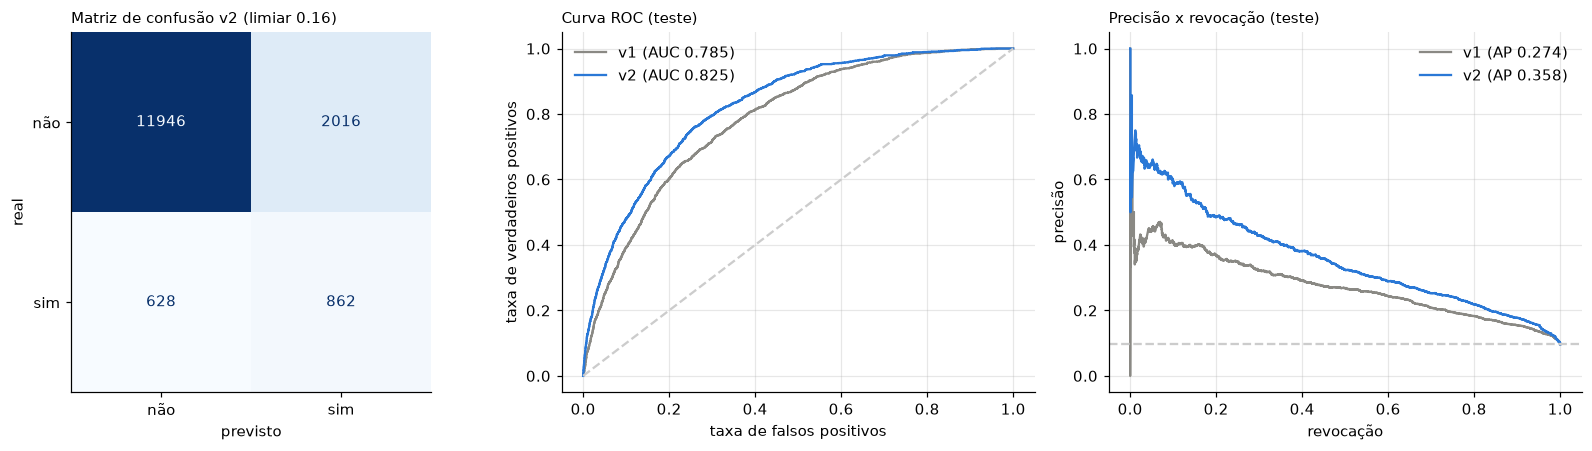

           previsto: não  previsto: sim
real: não          11946           2016
real: sim            628            862


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay.from_predictions(y_te, p_te_v2 >= limiar_v2, display_labels=["não", "sim"], cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title(f"Matriz de confusão v2 (limiar {limiar_v2})", loc="left", fontsize=10)
ax[0].grid(False); ax[0].set_xlabel("previsto"); ax[0].set_ylabel("real")
for nome, p, cor in [("v1", p_te_v1, CINZA), ("v2", p_te_v2, AZUL)]:
    fpr, tpr, _ = roc_curve(y_te, p); pr, rc, _ = precision_recall_curve(y_te, p)
    ax[1].plot(fpr, tpr, color=cor, label=f"{nome} (AUC {M.roc_auc_score(y_te, p):.3f})")
    ax[2].plot(rc, pr, color=cor, label=f"{nome} (AP {M.average_precision_score(y_te, p):.3f})")
ax[1].plot([0, 1], [0, 1], ls="--", color="#cccccc"); ax[1].set_xlabel("taxa de falsos positivos"); ax[1].set_ylabel("taxa de verdadeiros positivos")
ax[1].set_title("Curva ROC (teste)", loc="left", fontsize=10); ax[1].legend(frameon=False)
ax[2].axhline(y_te.mean(), ls="--", color="#cccccc"); ax[2].set_xlabel("revocação"); ax[2].set_ylabel("precisão")
ax[2].set_title("Precisão x revocação (teste)", loc="left", fontsize=10); ax[2].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "04_avaliacao_teste.png", bbox_inches="tight"); plt.show()
print(M.matriz_confusao(y_te, p_te_v2, limiar_v2))

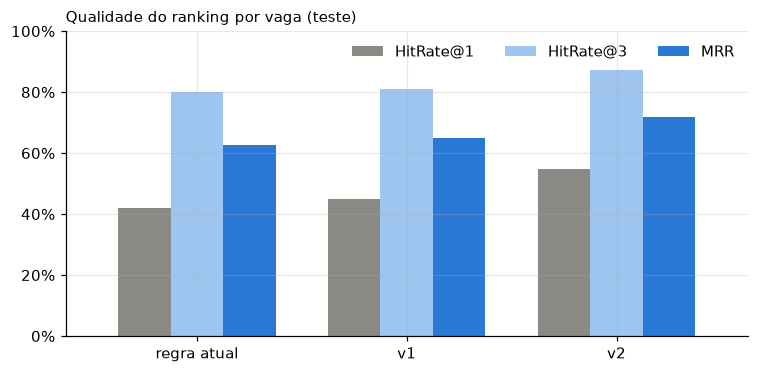

In [20]:
r = ranking.T[["hit_rate@1", "hit_rate@3", "mrr"]]
r.plot.bar(figsize=(8, 3.6), color=[CINZA, "#9ec5f0", AZUL], width=0.75)
plt.xticks(rotation=0); plt.ylim(0, 1); plt.legend(["HitRate@1", "HitRate@3", "MRR"], frameon=False, ncol=3)
plt.title("Qualidade do ranking por vaga (teste)", loc="left", fontsize=10)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.savefig(FIG / "05_ranking.png", bbox_inches="tight"); plt.show()

**Leitura dos resultados no teste**
- No ranking, que é o uso real do modelo, a v2 coloca o freelancer que deu certo **em primeiro lugar em cerca de 55% das vagas**, contra 42% da regra atual (ordenar pela nota). Entre os 3 primeiros, acerta em ~87% das vagas.
- Como classificador, a v2 encontra ~58% dos matches bem-sucedidos (revocação) com precisão de ~30%. A precisão parece baixa, mas é limitada pela própria natureza do problema: em cada vaga só **um** candidato é contratado, então vários bons candidatos ficam com rótulo 0.
- A matriz de confusão mostra o custo do limiar escolhido: mais falsos positivos em troca de não perder matches. Para recomendação isso é aceitável, porque convidar um freelancer a mais custa pouco.

### Underfitting ou overfitting?

- Na **v1**, treino, validação e teste ficam praticamente iguais e com desempenho baixo: sinal de **underfitting** (modelo com pouca informação).
- Na **v2** o desempenho sobe em todas as métricas, e treino, validação e teste continuam muito próximos (diferenças de centésimos no ROC-AUC e no PR-AUC): **não há overfitting**. A regularização da logística e o número grande de exemplos por atributo ajudam.
- No Gradient Boosting, a busca mostrou PR-AUC de treino bem acima do de validação (tabela da seção 9), sinal de que ele começava a decorar o treino. Esse foi mais um motivo para ficar com o modelo linear.
- O teste é de meses posteriores ao treino e mesmo assim o desempenho se mantém: o modelo **generaliza para o futuro**.

## 11. Interpretação do modelo
Importância por permutação no teste: quanto o PR-AUC cai quando os valores de um atributo são embaralhados.

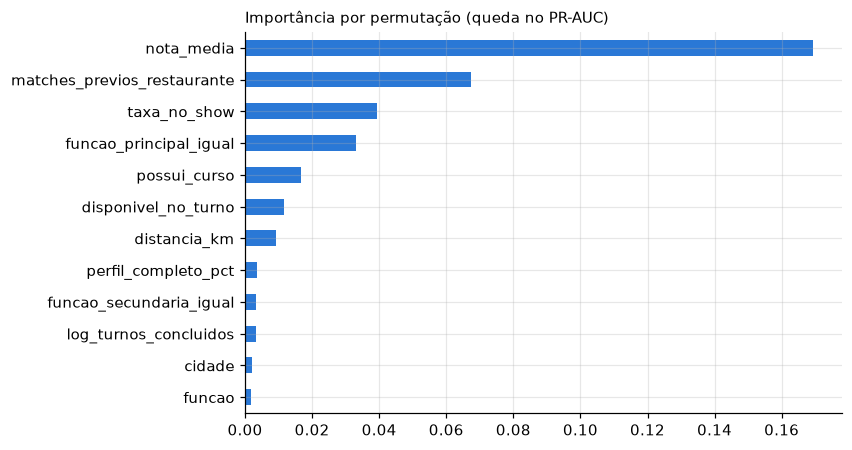

In [21]:
amostra = teste.sample(6000, random_state=42)
imp = permutation_importance(v2, amostra[P.FEATURES_V2], amostra.match_sucesso, scoring="average_precision",
                             n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=P.FEATURES_V2).sort_values().tail(12)
imp.plot.barh(figsize=(7, 4.5), color=AZUL)
plt.title("Importância por permutação (queda no PR-AUC)", loc="left", fontsize=10)
plt.savefig(FIG / "06_importancia.png", bbox_inches="tight"); plt.show()

Os atributos mais importantes fazem sentido para o negócio: **nota média** (qualidade), **histórico com o próprio restaurante**, **taxa de faltas** (confiabilidade) e **função principal**. Curso, disponibilidade no turno e distância vêm em seguida. Perfil completo, turnos concluídos, cidade e função quase não mudam o resultado, e a diferença entre a diária e a pretensão nem aparece entre os 12 primeiros.

## 12. Recomendação: exemplos de predições e ação sugerida

A recomendação acontece em **dois momentos**:

1. **Na publicação da vaga:** o modelo avalia todos os freelancers elegíveis (mesma cidade, função principal ou secundária), inclusive quem ainda não se candidatou, e os primeiros do ranking recebem convite.
2. **Depois das candidaturas:** os candidatos são ordenados para o restaurante, e a **maior probabilidade entre eles** define a ação para a vaga.

### 12.1 Regra de ação e sua justificativa
Os limiares da ação são os quartis da maior probabilidade por vaga na **validação cruzada do treino** (25% das vagas com candidatos mais fracos = risco; 25% mais fortes = boa opção). Depois, no **teste**, conferimos se as faixas separam as vagas que de fato terminaram com um match bem-sucedido.

Limiares (quartis da validação no treino): (np.float64(0.15), np.float64(0.33))


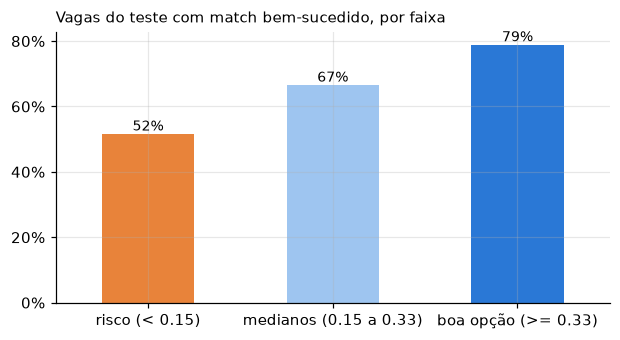

,vagas,taxa_real_de_sucesso,% das vagas
faixa,,,
risco (< 0.15),546,0.516,0.245
medianos (0.15 a 0.33),997,0.666,0.447
boa opção (>= 0.33),689,0.790,0.309


In [22]:
por_vaga_tr = treino.assign(p=oof[escolhido]).groupby("id_vaga").p.max()
limiares = tuple(np.round(por_vaga_tr.quantile([0.25, 0.75]).values, 2))
rotulos = [f"risco (< {limiares[0]})", f"medianos ({limiares[0]} a {limiares[1]})", f"boa opção (>= {limiares[1]})"]
por_vaga = teste.groupby("id_vaga").agg(melhor_prob=("score_v2", "max"), sucesso=("match_sucesso", "max"))
por_vaga["faixa"] = pd.cut(por_vaga.melhor_prob, [0, *limiares, 1], labels=rotulos, right=False)
faixas = por_vaga.groupby("faixa", observed=True).agg(vagas=("sucesso", "size"), taxa_real_de_sucesso=("sucesso", "mean"))
faixas["% das vagas"] = faixas.vagas / faixas.vagas.sum()
print("Limiares (quartis da validação no treino):", limiares)
ax = faixas.taxa_real_de_sucesso.plot.bar(figsize=(6.5, 3.2), color=[LARANJA, "#9ec5f0", AZUL], rot=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_xlabel("")
for i, v in enumerate(faixas.taxa_real_de_sucesso): ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
plt.title("Vagas do teste com match bem-sucedido, por faixa", loc="left", fontsize=10)
plt.savefig(FIG / "07_faixas_acao.png", bbox_inches="tight"); plt.show()
faixas.round(3)

As faixas separam bem as vagas: quando o melhor candidato tem probabilidade baixa, a vaga termina com sucesso bem menos vezes do que quando há um candidato forte. Por isso cada faixa recebe uma ação diferente:

| Faixa (maior probabilidade entre os candidatos) | Ação recomendada |
|---|---|
| Boa opção | destacar o 1º do ranking para o restaurante contratar |
| Medianos | mostrar o ranking e convidar mais 3 freelancers elegíveis |
| Risco | nova rodada de convites aos 5 melhores elegíveis que não se candidataram + aviso ao restaurante (rever diária ou horário) |

### 12.2 Exemplos de predições: vagas do período de teste
Para cada vaga: (a) os convites que o sistema teria enviado na publicação e (b) os candidatos reais ordenados pelo modelo, comparados com o que aconteceu (`match_real`).

In [23]:
fre_l, rest_l, vagas_l = limpos["freelancers"], limpos["restaurantes"], limpos["vagas"]
vagas_idx, rest_idx = vagas_l.set_index("id_vaga"), rest_l.set_index("id_restaurante")
sucessos = base[base.match_sucesso == 1]

def historico_ate(data):
    # matches bem-sucedidos de cada par (restaurante, freelancer) em vagas publicadas antes da data
    return sucessos[sucessos.data_publicacao < data].groupby(["id_restaurante", "id_freela"]).size().to_dict()

def vaga_do_conjunto(id_vaga):
    v = vagas_idx.loc[id_vaga]; r = rest_idx.loc[v.id_restaurante]
    return {"id_vaga": id_vaga, "id_restaurante": v.id_restaurante, "cidade": r.cidade, "segmento": r.segmento,
            "x_km": r.x_km, "y_km": r.y_km, "funcao": v.funcao, "periodo": v.periodo,
            "data_turno": str(v.data_turno), "valor_diaria": float(v.valor_diaria),
            "horas_antecedencia": float(v.horas_antecedencia)}

exemplos = [por_vaga[por_vaga.faixa == f].sample(1, random_state=7).index[0] for f in reversed(rotulos)]
for idv in exemplos:
    vaga = vaga_do_conjunto(idv)
    print(f"\n{'=' * 100}\nVaga {idv}: {vaga['funcao']} em {vaga['cidade']} ({vaga['segmento']}), {vaga['periodo']}, "
          f"turno {vaga['data_turno'][:16]}, diária R$ {vaga['valor_diaria']:.0f}")
    historico = historico_ate(vagas_idx.loc[idv, "data_publicacao"])
    convites, n = R.convidar(vaga, v2, fre_l, historico, k=5)
    print(f"(a) Convites na publicação: {n} freelancers elegíveis avaliados, 5 primeiros:")
    display(convites.round({"prob_match": 3, "nota_media": 2}))
    rk, resumo = R.ranquear_candidatos(teste[teste.id_vaga == idv], v2, limiares)
    print(f"(b) Candidatos ordenados pelo modelo | {resumo['situacao']} (maior prob. {resumo['melhor_prob']:.2f})")
    print("    Ação:", resumo["acao"])
    display(rk[["posicao", "id_freela", "prob_match", "distancia_km", "nota_media", "motivos", "match_sucesso"]]
            .rename(columns={"match_sucesso": "match_real"}).round({"prob_match": 3, "nota_media": 2}))


Vaga V06196: Auxiliar de Cozinha em Itaqui (Churrascaria), tarde, turno 2026-08-31 12:00, diária R$ 120
(a) Convites na publicação: 30 freelancers elegíveis avaliados, 5 primeiros:


,posicao,id_freela,prob_match,distancia_km,nota_media,matches_previos_restaurante,motivos
0,1,F00042,0.871,1.91,4.57,4,"já trabalhou 4x aqui, mora perto (1.9 km)"
1,2,F00502,0.757,1.86,4.96,4,"já trabalhou 4x aqui, mora perto (1.9 km), not..."
2,3,F01774,0.605,2.38,4.28,3,"já trabalhou 3x aqui, mora perto (2.4 km), qua..."
3,4,F00825,0.231,1.60,4.65,1,"já trabalhou 1x aqui, mora perto (1.6 km), not..."
4,5,F00803,0.163,0.20,4.02,1,"já trabalhou 1x aqui, mora perto (0.2 km)"


(b) Candidatos ordenados pelo modelo | Boa opção entre os candidatos (maior prob. 0.87)
    Ação: Destacar o 1º do ranking para o restaurante contratar.


,posicao,id_freela,prob_match,distancia_km,nota_media,motivos,match_real
0,1,F00042,0.871,1.91,4.57,"já trabalhou 4x aqui, mora perto (1.9 km)",1
1,2,F00825,0.231,1.60,4.65,"já trabalhou 1x aqui, mora perto (1.6 km), not...",0
2,3,F00414,0.054,1.05,4.11,"mora perto (1.1 km), quase nunca falta",0
3,4,F00390,0.050,1.32,4.67,"mora perto (1.3 km), nota 4.7, função secundária",0



Vaga V06323: Bartender em Porto Alegre (Churrascaria), noite, turno 2026-09-04 22:00, diária R$ 175
(a) Convites na publicação: 63 freelancers elegíveis avaliados, 5 primeiros:


...

,posicao,id_freela,prob_match,distancia_km,nota_media,motivos,match_real
0,1,F00351,0.240,2.90,4.73,"mora perto (2.9 km), nota 4.7",0
1,2,F00400,0.095,2.62,4.00,"mora perto (2.6 km), quase nunca falta",1
2,3,F01076,0.035,3.86,4.01,"quase nunca falta, função secundária",0
3,4,F00496,0.020,8.50,4.34,função secundária,0
4,5,F00950,0.011,5.91,3.70,função secundária,0
5,6,F01703,0.003,8.00,3.32,função secundária,0



Vaga V06951: Cozinheiro em Santa Maria (Buffet), noite, turno 2026-10-01 22:00, diária R$ 200
(a) Convites na publicação: 98 freelancers elegíveis avaliados, 5 primeiros:


,posicao,id_freela,prob_match,distancia_km,nota_media,matches_previos_restaurante,motivos
0,1,F01221,0.379,7.84,4.92,0,nota 4.9
1,2,F01669,0.330,4.40,5.00,0,"nota 5.0, quase nunca falta"
2,3,F01550,0.297,5.47,5.00,0,"nota 5.0, quase nunca falta"
3,4,F00513,0.292,1.74,4.83,0,"mora perto (1.7 km), nota 4.8"
4,5,F00523,0.267,3.93,4.70,0,"nota 4.7, quase nunca falta"


(b) Candidatos ordenados pelo modelo | Risco de não preencher (maior prob. 0.14)
    Ação: Nova rodada de convites aos 5 melhores elegíveis que não se candidataram e aviso ao restaurante, sugerindo rever a diária ou o horário.


,posicao,id_freela,prob_match,distancia_km,nota_media,motivos,match_real
0,1,F01671,0.145,5.98,5.00,"nota 5.0, quase nunca falta, função secundária",0
1,2,F00899,0.052,3.11,3.93,-,0
2,3,F00163,0.018,3.09,4.30,função secundária,0


**Leitura dos exemplos**
- Na vaga com **boa opção**, o modelo colocou em 1º o freelancer que de fato deu certo, e ele já estava entre os convites da publicação.
- Na vaga com **candidatos medianos**, o match real ficou em 2º lugar; a ação de ampliar convites faz sentido porque nenhum candidato era forte.
- Na vaga de **risco**, os freelancers que o sistema convidaria na publicação têm probabilidade bem maior que a dos candidatos que apareceram, e nenhum candidato deu certo. É exatamente o caso em que o convite ativo faz diferença.

### 12.3 Simulação: e se o restaurante aumentar a diária?

In [24]:
vaga_risco = vaga_do_conjunto(exemplos[-1])
display(R.simular_diaria(vaga_risco, v2, fre_l, historico_ate(vagas_idx.loc[exemplos[-1], "data_publicacao"])).round(3))

,aumento,valor_diaria,melhor_prob,media_top5
0,0%,200,0.379,0.313
1,10%,220,0.379,0.313
2,20%,240,0.379,0.313
3,30%,260,0.379,0.313


Pelo modelo, aumentar a diária praticamente não muda a chance de sucesso (a diferença de diária nem aparece entre os atributos importantes da seção 11): o que mais pesa é ter freelancers **próximos, confiáveis, disponíveis e com histórico no restaurante**. Para vagas de risco, a recomendação mais eficaz é ampliar os convites para os elegíveis certos, e não apenas pagar mais. Essa leitura evita oferecer ao restaurante uma solução que o próprio modelo indica que não resolve o problema.

In [25]:
# Salva o modelo final e as métricas
joblib.dump(v2, "models/modelo_v2.joblib")
params = buscas[escolhido].best_params_ if escolhido in buscas else {}
metricas = {"modelo_escolhido": escolhido, "limiar_classificacao": limiar_v2,
            "hiperparametros": {k.replace("modelo__", ""): v for k, v in params.items()},
            "limiares_acao": limiares, "teste_v1": final["v1 (teste)"].to_dict(),
            "teste_v2": final["v2 (teste)"].to_dict(), "ranking_teste": ranking.to_dict()}
Path("models/metricas.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False, default=float))
print(json.dumps(metricas, indent=2, ensure_ascii=False, default=float)[:900])

{
  "modelo_escolhido": "Regressão logística v2 (ajustada)",
  "limiar_classificacao": 0.16,
  "hiperparametros": {
    "C": 0.01,
    "class_weight": null
  },
  "limiares_acao": [
    0.15,
    0.33
  ],
  "teste_v1": {
    "acuracia": 0.814,
    "precisao": 0.264,
    "revocacao": 0.518,
    "f1": 0.35,
    "roc_auc": 0.785,
    "pr_auc": 0.274
  },
  "teste_v2": {
    "acuracia": 0.829,
    "precisao": 0.3,
    "revocacao": 0.579,
    "f1": 0.395,
    "roc_auc": 0.825,
    "pr_auc": 0.358
  },
  "ranking_teste": {
    "regra atual": {
      "hit_rate@1": 0.419,
      "hit_rate@3": 0.8,
      "hit_rate@5": 0.934,
      "mrr": 0.625,
      "ndcg@5": 0.695
    },
    "v1": {
      "hit_rate@1": 0.45,
      "hit_rate@3": 0.811,
      "hit_rate@5": 0.941,
      "mrr": 0.649,
      "ndcg@5": 0.716
    },
    "v2": {
      "hit_rate@1": 0.547,
      "hit_rate@3": 0.872,
      "hit_rate@5": 


## 13. Limitações e possibilidades de evolução

**Limitações**
- **Dados simulados:** as relações seguem a lógica do negócio, mas os números não são da operação real da UmFreela. O próximo passo é treinar com o histórico real, anonimizado.
- **Viés de seleção:** o modelo aprende só com quem se candidatou. Ao convidar freelancers que não se candidataram, a probabilidade pode estar superestimada para quem não teria interesse na vaga.
- **Um contratado por vaga:** a cada vaga só um candidato pode dar certo, então os outros recebem 0 mesmo sendo bons. Isso limita a precisão máxima possível.
- **Atributos estáticos do freelancer:** nota e taxas de falta são uma foto do cadastro; em produção deveriam ser recalculadas na data de cada vaga.
- **Recomendação por regras:** as faixas de ação foram definidas a partir da análise e ainda não foram testadas com restaurantes reais.

**Evolução**
- Teste A/B: metade das vagas com o ranking do modelo, metade com a regra atual, medindo a taxa de preenchimento.
- Modelo de ranking dedicado (Learning to Rank, por exemplo LightGBM com objetivo *lambdarank*).
- Equilíbrio de oportunidades: limitar quantos convites cada freelancer recebe, para não concentrar as vagas sempre nos mesmos.
- Calibração das probabilidades e monitoramento de deriva com retreino mensal.
- Integração no app: lista de candidatos já ordenada, convites automáticos na publicação e as ações da seção 12.